<a href="https://colab.research.google.com/github/beatrisAS/Desafio1_API_Streaming_Filmes_Python/blob/main/api/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Célula 01 · Importações**

**O que esta célula faz:** importa as bibliotecas que o notebook usa (arquivos, Google Colab, pandas e gráficos) e define configurações gerais, que valem para todos os gráficos.
**Não tem lacunas:** copie e execute.

In [276]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### **Célula 02 · Carregar os arquivos CSV**

**O que esta célula faz:** conecta o Google Drive, guarda os CSV na pasta `Colab Notebooks/desafios/dados` e lê os dois arquivos em DataFrames: `df_dimensao` e `df_fato`. Os nomes das tabelas são os mesmos dos arquivos, sem o `.csv`.

*  Na primeira execução, o Colab pede autorização para acessar o Drive.
* Se algum arquivo ainda não estiver na pasta, abre a janela de seleção: escolha os **2 CSV de uma vez**. O código identifica cada um pelo nome (o nome do arquivo precisa conter o nome da tabela) e salva já com o nome certo.
*  Nas próximas execuções, lê direto do Drive, sem pedir envio.



In [277]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "filmes"   # ex.: "livros"
NOME_TABELA_FATO = "visualizacoes"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
filmes -> 10300 linhas
visualizacoes -> 55000 linhas


### **Célula 03 · Conhecendo a tabela dimensão**

**O que esta célula faz:** mostra quantas linhas e colunas tem a tabela dimensão e as 5 primeiras linhas. Olhe a chave primária e as colunas de cadastro. **Não tem lacunas.**

In [278]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10300 linhas e 7 colunas (variáveis)


,filme_id,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,Segredo Vale,animação,1991,85,L,Pietra Brito
1,2,Distante Destino,animação,2002,155,14,Luiz Miguel da Conceição
2,3,Dourado Deserto,ação,1995,128,L,Joaquim da Mota
3,4,Sombra Caminho,comédia,2016,120,16,Milena Cavalcante
4,5,Escarlate Vale,romance,1992,101,L,Marina Pimenta


### **Célula 04 · Conhecendo a tabela fato**

O que esta célula faz: o mesmo para a tabela fato. Olhe a chave estrangeira, as datas e as colunas numéricas. **Não tem lacunas.**

In [279]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False


### **Célula 05 · Tipos das colunas**

**O que esta célula faz:** mostra o tipo de cada coluna e quantos valores estão preenchidos.

In [280]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   visualizacao_id      55000 non-null  int64 
 1   filme_id             55000 non-null  int64 
 2   usuario_id           55000 non-null  int64 
 3   data_hora_inicio     55000 non-null  object
 4   tempo_assistido_min  55000 non-null  int64 
 5   dispositivo          55000 non-null  object
 6   concluido            55000 non-null  bool  
dtypes: bool(1), int64(4), object(2)
memory usage: 2.6+ MB


### **Célula 06 · Valores ausentes**

**O que esta célula faz:** conta os valores ausentes de cada coluna da tabela fato.

In [281]:
# Conta valores ausentes em cada coluna e exibe o resultado em uma tabela.
valores_ausentes = pd.DataFrame({
    "Coluna": df_fato.columns,
    "Valores ausentes": df_fato.isna().sum().values
})
display(valores_ausentes)


,Coluna,Valores ausentes
0,visualizacao_id,0
1,filme_id,0
2,usuario_id,0
3,data_hora_inicio,0
4,tempo_assistido_min,0
5,dispositivo,0
6,concluido,0


### **Célula 07 · Linhas duplicadas**

**O que esta célula faz:** conta os registros repetidos da tabela fato.

In [282]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### **Célula 08 · Chave estrangeira**

**O que esta célula faz:** confere se todo registro da fato aponta para um ID que existe na dimensão. Preencha com os nomes das colunas que você identificou na documentação do seu tema.

In [283]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "filme_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "filme_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


**Leitura da conferência**

- A tabela fato `visualizacoes` tem **55.000 registros e 7 colunas.** Não há linhas duplicadas.
- A chave estrangeira `filme_id` bate com a tabela dimensão` filmes`: todos os IDs correspondem a um filme cadastrado.
- A coluna analisada, `tempo_assistido_min`, não tem valores ausentes.
- Não foram encontrados valores ausentes nas demais colunas da tabela fato; portanto, não foi necessário avaliar campos vazios como erro ou situação esperada.

### **Célula 09 · Checar a coluna numérica**

**O que esta célula faz:** guarda a coluna numérica escolhida no Passo 1 como uma série (`serie_numerica`) e mostra quantos valores estão preenchidos e quantos estão ausentes.

In [284]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_assistido_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### **Célula 10 · Medidas estatísticas**

**O que esta célula faz:** calcula média, mediana, moda, desvio padrão, variância, mínimo, máximo e amplitude da coluna escolhida. O pandas **ignora os valores ausentes** no cálculo. **Não tem lacunas.**

In [285]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,90.93
Mediana,88.00
Moda,74.00
Desvio padrão,35.26
Variância,1243.05
Mínimo,2.00
Máximo,183.00
Amplitude,181.00


Média - mediana: 2.93


**Insights:**

- **A média de tempo_assistido_min é 90,93 minutos** por visualização. Esse é o tempo médio assistido nos registros analisados.
- **A mediana de tempo_assistido_min é 88 minutos.** Metade das visualizações teve tempo assistido de até 88 minutos e metade teve 88 minutos ou mais. Ela é próxima da média, então as duas medidas indicam um centro semelhante.

- **O desvio padrão de tempo_assistido_min é 35,26 minutos.** Os tempos variam consideravelmente em torno da média.

- **Leitura complementar:** A mediana de 88 minutos serve como referência do tempo típico assistido; para responder à pergunta de negócio sobre não conclusão, comparar a proporção de registros com `concluido = False` entre dispositivos.

### **Célula 11 · Juntar a fato com a dimensão**

**O que esta célula faz:** junta a tabela fato com a dimensão pela chave estrangeira (`COLUNA_FK`, da fato, com `COLUNA_ID`, da dimensão) e guarda o resultado em `df_completo`. As duas tabelas precisam ter **o mesmo número de linhas** depois da junção. Se aumentar, a junção duplicou registros. Não tem lacunas.

In [286]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

# Mostra as primeiras linhas da tabela resultante da junção.
display(df_completo.head())

Linhas da fato: 55000 | depois da junção: 55000


,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False,Silencioso Oceano 2252,ação,2006,108,18,Maria Laura Cassiano
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False,Eterno Horizonte 6588,terror,1988,128,14,Jade Rocha
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False,Sombra Vento 5799,drama,1997,84,10,Dr. Asafe Pires
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False,Fronteira Deserto 2255,ação,1995,183,12,Isabel Mendes
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False,Silencioso Oceano 8759,comédia,2004,168,10,Theo das Neves


### **Célula 12 · Comparar visualizações não concluídas por dispositivo**

**O que esta célula faz:** conta as visualizações por dispositivo e calcula quantas e qual porcentagem estão marcadas como não concluídas.


In [287]:
# Compara a quantidade e a proporção de visualizações não concluídas por dispositivo.
por_dispositivo = (
    df_fato.groupby("dispositivo")
    .agg(
        total_visualizacoes=("concluido", "size"),
        nao_concluidas=("concluido", lambda status: (~status).sum()),
        taxa_nao_conclusao_pct=("concluido", lambda status: (~status).mean() * 100)
    )
    .round(2)
    .sort_values("taxa_nao_conclusao_pct", ascending=False)
)
display(por_dispositivo)


,total_visualizacoes,nao_concluidas,taxa_nao_conclusao_pct
dispositivo,,,
computador,8188,6837,83.50
console,2734,2280,83.39
smart_tv,21994,18273,83.08
tablet,5581,4628,82.92
celular,16503,13620,82.53


### Leitura por dispositivo

O computador tem a maior taxa de visualizações não concluídas: **83,50%** (**6.837 de 8.188**). O console vem em seguida, com **83,39%** (**2.280 de 2.734**), apenas **0,11 ponto percentual** abaixo. A menor taxa é a do celular, **82,53%**. Em quantidade absoluta, a smart TV tem mais visualizações não concluídas (**18.273**), mas também reúne muito mais registros. Assim, pela proporção, o computador é o dispositivo que merece investigação primeiro.

`concluido=False` é usado aqui como indicador de visualização não concluída; isso não comprova, por si só, que a pessoa abandonou definitivamente o filme.


### **Célula 13 · Comparar visualizações não concluídas por gênero**

**O que esta célula faz:** compara, para cada gênero, a quantidade total de visualizações, as não concluídas e a respectiva taxa percentual.


In [288]:
# Compara visualizações não concluídas por gênero do filme.
por_genero = (
    df_completo.groupby("genero")
    .agg(
        total_visualizacoes=("concluido", "size"),
        nao_concluidas=("concluido", lambda status: (~status).sum()),
        taxa_nao_conclusao_pct=("concluido", lambda status: (~status).mean() * 100)
    )
    .round(2)
    .sort_values("taxa_nao_conclusao_pct", ascending=False)
)
display(por_genero)


,total_visualizacoes,nao_concluidas,taxa_nao_conclusao_pct
genero,,,
animação,5629,4744,84.28
documentário,4111,3424,83.29
drama,10675,8881,83.19
ficção científica,7340,6095,83.04
terror,5678,4702,82.81
comédia,7966,6583,82.64
romance,4893,4042,82.61
ação,8708,7167,82.30


### Leitura por gênero

A animação tem a maior taxa de visualizações não concluídas, **84,28%** (**4.744 de 5.629**). A ação tem a menor taxa, **82,30%** (**7.167 de 8.708**), uma diferença de **1,98 ponto percentual** entre esses gêneros. A taxa é elevada em todos os gêneros; essa comparação mostra uma associação, não explica por que as visualizações não foram concluídas.


### **Célula 14 · Regra do IQR**

**O que esta célula faz:** usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e apresenta em uma tabela os quartis, os limites, a quantidade de candidatos a outlier e os valores extremos. **Não tem lacunas.**

In [289]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Separa os valores dentro dos limites e conta os candidatos a outlier.
sem_outliers = serie_numerica[serie_numerica.between(limite_inferior, limite_superior)]
outliers = serie_numerica[~serie_numerica.between(limite_inferior, limite_superior)]
qtd_outliers = outliers.count()

# Resume os resultados da verificação em uma tabela.
resumo_iqr = pd.DataFrame({
    "Verificação": [
        "Primeiro quartil (Q1)",
        "Terceiro quartil (Q3)",
        "Intervalo interquartil (IQR)",
        "Limite inferior",
        "Limite superior",
        "Candidatos a outlier",
        "Total de registros analisados",
        "Menores valores observados (5)",
        "Maiores valores observados (5)",
    ],
    "Resultado": [
        round(q1, 2),
        round(q3, 2),
        round(iqr, 2),
        round(limite_inferior, 2),
        round(limite_superior, 2),
        f"{qtd_outliers} de {serie_numerica.count()}",
        serie_numerica.count(),
        str(serie_numerica.nsmallest(5).tolist()),
        str(serie_numerica.nlargest(5).tolist()),
    ]
})
display(resumo_iqr)

,Verificação,Resultado
0,Primeiro quartil (Q1),65.0
1,Terceiro quartil (Q3),116.0
2,Intervalo interquartil (IQR),51.0
3,Limite inferior,-11.5
4,Limite superior,192.5
5,Candidatos a outlier,0 de 55000
6,Total de registros analisados,55000
7,Menores valores observados (5),"[2, 3, 4, 4, 5]"
8,Maiores valores observados (5),"[183, 183, 183, 183, 183]"


### **Célula 15 · Medidas com e sem os candidatos a outlier**

**O que esta célula faz:** compara média, mediana e desvio padrão com e sem os valores marcados na Célula 14. **Não tem lacunas.**

In [290]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,90.93,90.93
Mediana,88.00,88.00
Desvio padrão,35.26,35.26


**Leitura e decisão registrada**

- A regra do IQR marcou **0 valores** como candidatos a outlier. Os limites são **−11,5 a 192,5 minutos**. Como nenhum valor foi sinalizado, as medidas não mudam: média **90,93 minutos**, mediana **88 minutos** e desvio padrão **35,26 minutos**, tanto com quanto sem os candidatos.
- **Decisão:** manter todos os registros; não há valores sinalizados para corrigir ou excluir.
- **Valores ausentes:** a coluna `tempo_assistido_min` e as demais colunas da tabela fato não apresentam valores ausentes; portanto, nenhum valor foi preenchido ou removido.


### Célula 16 · Assimetria (skew)

**O que esta célula faz:** calcula o quanto a distribuição se inclina para um dos lados.



In [291]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 0.22


### **Célula 17 · Percentis**

**O que esta célula faz:** mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.

In [292]:
# Percentis do tempo assistido apresentados em uma tabela.
percentis = pd.DataFrame({
    "Percentual dos registros": ["10%", "25%", "50% (mediana)", "75%", "90%"],
    "Tempo assistido (minutos)": serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).values
})
percentis["Tempo assistido (minutos)"] = percentis["Tempo assistido (minutos)"].round(2)
display(percentis)


,Percentual dos registros,Tempo assistido (minutos)
0,10%,47.0
1,25%,65.0
2,50% (mediana),88.0
3,75%,116.0
4,90%,141.0


### **Célula 18 · Quantidade de valores por faixa**

**O que esta célula faz:** divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.


In [293]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_assistido_min,
"(1.819, 38.2]",3231
"(38.2, 74.4]",16341
"(74.4, 110.6]",19183
"(110.6, 146.8]",12177
"(146.8, 183.0]",4068


**Leitura da distribuição**

- A assimetria é **0,22**, indicando uma distribuição quase equilibrada, com leve cauda para valores mais altos.
- O percentil 75 é **116 minutos** e o percentil 90 é **141 minutos**: 75% dos registros têm até 116 minutos assistidos e 90% têm até 141 minutos.
- Na primeira faixa (aproximadamente **1,8 a 38,2 minutos**) há **3.231 registros**; na faixa mais alta (aproximadamente **146,8 a 183 minutos**) há **4.068**. A maior concentração está entre **74,4 e 110,6 minutos**, com **19.183 registros**.
- Em palavras: a maior parte dos tempos se concentra nas faixas intermediárias, e há menos registros nos extremos.


###**Célula 19 · Histograma**

**O que esta célula faz:** desenha o histograma da coluna analisada, com a curva da distribuição (`kde=True`) e as linhas da **média** (vermelha) e da **mediana** (verde tracejada).

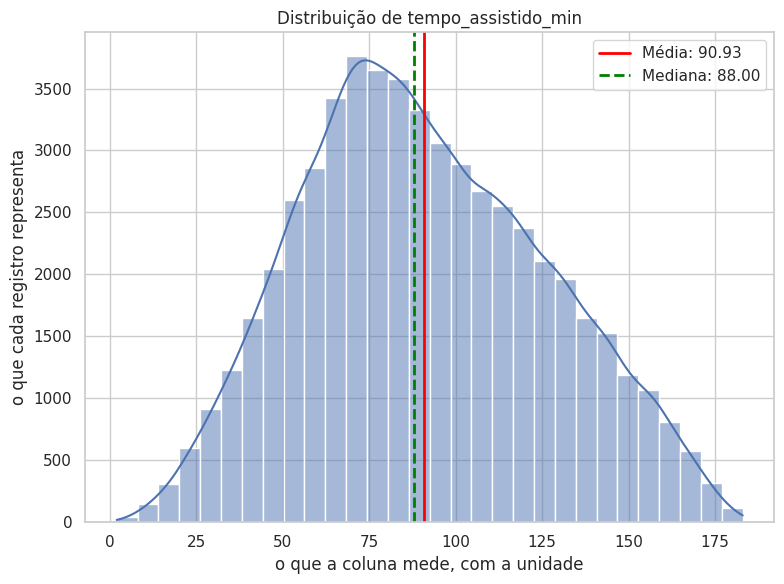

In [294]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

### **Célula 20 · Boxplot**

**O que esta célula faz:** desenha o boxplot: a caixa é a faixa central (25% a 75%) e os pontos fora são candidatos a outlier. A linha vermelha marca a média.

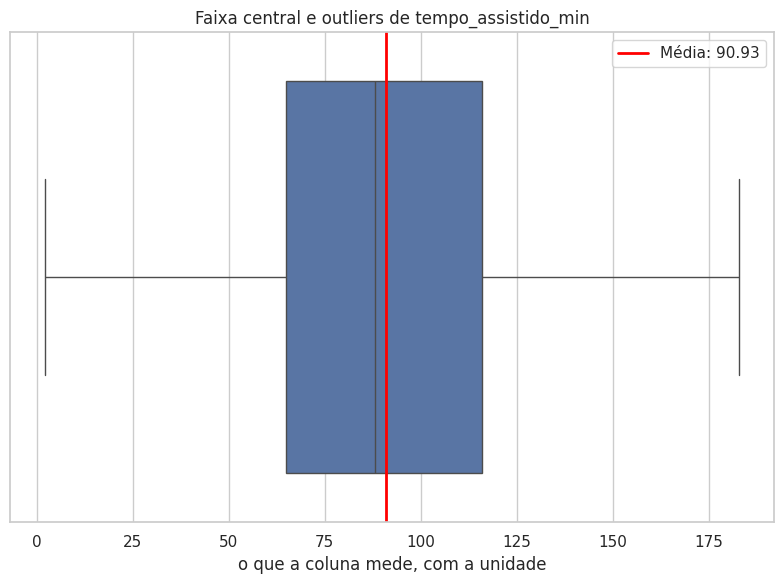

In [295]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

### **Pergunta de negócio: Em qual dispositivo há maior proporção de visualizações não concluídas?**

- **Evidência 1:** No computador, **6.837 de 8.188 visualizações não foram concluídas**, uma taxa de **83,50%**, a maior entre os dispositivos.

- **Evidência 2:** No console, a taxa é **83,39%** (**2.280 de 2.734**); é apenas **0,11 ponto percentual** menor. A smart TV tem a maior quantidade absoluta de não conclusões (**18.273**), mas também tem a maior quantidade de visualizações (**21.994**).

- **Leitura complementar:** Por gênero, animação apresenta a maior taxa de não conclusão (**84,28%**); ação, a menor (**82,30%**).

- **Recomendação em uma frase:** Investigar primeiro a experiência de visualização no computador e comparar os motivos de não conclusão entre dispositivos antes de decidir mudanças na plataforma.

- **Limites da análise:** Os dados são fictícios. `concluido=False` indica que a visualização não foi marcada como concluída e é usado como aproximação de abandono, mas não prova abandono definitivo. Não foram encontrados valores ausentes; a verificação de outliers pelo IQR foi feita sobre `tempo_assistido_min`, não sobre a taxa de não conclusão.
